# Otto Multiobjective

## Key Features

- 12M real-world anonymized user sessions
- 220M events, consiting of `clicks`, `carts` and `orders`
- 1.8M unique articles in the catalogue
- Ready to use data in `.jsonl` format
- Evaluation metrics for single and multi-objective tasks

## Dataset Statistics

| Dataset |  #sessions |    #items |     #events |     #clicks |     #carts |   #orders | Density [%] |
| :------ | ---------: | --------: | ----------: | ----------: | ---------: | --------: | ----------: |
| Train   | 12.899.779 | 1.855.603 | 216.716.096 | 194.720.954 | 16.896.191 | 5.098.951 |      0.0005 |
| Test    |  1.671.803 | 1.019.357 |  13.851.293 |  12.340.303 |  1.155.698 |   355.292 |      0.0005 |

|                           |  mean |   std |  min |  50% |  75% |  90% |  95% |  max |
| :------------------------ | ----: | ----: | ---: | ---: | ---: | ---: | ---: | ---: |
| Train #events per session | 16.80 | 33.58 |    2 |    6 |   15 |   39 |   68 |  500 |
| Test  #events per session |  8.29 | 13.74 |    2 |    4 |    8 |   18 |   28 |  498 |

<details>
    <summary><strong>#events per session histogram (90th percentile)</strong></summary>
    <img src=".readme/events_per_session_p90.svg" width="800px">
</details>

|                        |   mean |    std |  min |  50% |  75% |  90% |  95% |    max |
| :--------------------- | -----: | -----: | ---: | ---: | ---: | ---: | ---: | -----: |
| Train #events per item | 116.79 | 728.85 |    3 |   20 |   56 |  183 |  398 | 129004 |
| Test #events per item  |  13.59 |  70.48 |    1 |    3 |    9 |   24 |   46 |  17068 |

<details>
    <summary><strong>#events per item histogram (90th percentile)</strong></summary>
    <img src=".readme/events_per_item_p90.svg" width="800px">
</details>


In [1]:
%load_ext autoreload
%autoreload 2


In [7]:
import polars as pl
import polars_ds as pds
import testset

## convert json to parquet and type

In [4]:
type_map = dict(zip([0,1,2],["clicks","carts","orders"]))
type_e = pl.Enum(type_map.values())
train = train.with_columns(pl.from_epoch(pl.col("ts"),time_unit="s"), pl.col("type").cast(type_e))

In [59]:
type_map = dict(zip([0,1,2],["clicks","carts","orders"]))
type_e = pl.Enum(type_map.values())
test_full = (
    test_full
    .explode("events")
    .unnest("events")
    .with_columns(ts=pl.from_epoch(pl.col("ts"),time_unit='ms'), type=pl.col("type").cast(type_e))
)

In [4]:
train = train.with_columns(ts=pl.col("ts").dt.cast_time_unit('ms'))

In [6]:
train.write_parquet('data/train.parquet')

In [57]:
test_full = pl.read_ndjson("data/otto-recsys-test.jsonl")

In [53]:
test = test.with_columns(pl.from_epoch(pl.col("ts"),time_unit="s"), pl.col("type").cast(type_e))

## Analysis

In [8]:
train = pl.read_parquet("data/train.parquet").set_sorted("session")
#.with_columns(pl.from_epoch(pl.col("ts"),time_unit="s"), pl.col("type").cast(type_e))

In [5]:
train.head()

session,aid,ts,type
i32,i32,datetime[ms],enum
0,1517085,2022-07-31 22:00:00,"""clicks"""
0,1563459,2022-07-31 22:01:44,"""clicks"""
0,1309446,2022-08-01 15:23:59,"""clicks"""
0,16246,2022-08-01 15:28:39,"""clicks"""
0,1781822,2022-08-01 15:31:11,"""clicks"""


In [8]:
train = train.set_sorted("session")

In [11]:
max_ts = testset.get_max_ts(train)
max_ts

datetime.datetime(2022, 8, 28, 21, 59, 59)

In [ ]:
split_ts = max_ts - pl.duration(days=7)
is_after =pl.col('ts').first().over('session') > split_ts

zz = train.with_columns(is_after= is_after).partition_by('is_after',include_key=False)

[shape: (201_331_519, 5)
 ┌──────────┬─────────┬─────────────────────┬────────┬──────────┐
 │ session  ┆ aid     ┆ ts                  ┆ type   ┆ is_after │
 │ ---      ┆ ---     ┆ ---                 ┆ ---    ┆ ---      │
 │ i32      ┆ i32     ┆ datetime[ms]        ┆ enum   ┆ bool     │
 ╞══════════╪═════════╪═════════════════════╪════════╪══════════╡
 │ 0        ┆ 1517085 ┆ 2022-07-31 22:00:00 ┆ clicks ┆ false    │
 │ 0        ┆ 1563459 ┆ 2022-07-31 22:01:44 ┆ clicks ┆ false    │
 │ 0        ┆ 1309446 ┆ 2022-08-01 15:23:59 ┆ clicks ┆ false    │
 │ 0        ┆ 16246   ┆ 2022-08-01 15:28:39 ┆ clicks ┆ false    │
 │ 0        ┆ 1781822 ┆ 2022-08-01 15:31:11 ┆ clicks ┆ false    │
 │ …        ┆ …       ┆ …                   ┆ …      ┆ …        │
 │ 11098527 ┆ 1149209 ┆ 2022-08-21 22:02:15 ┆ clicks ┆ false    │
 │ 11098527 ┆ 151316  ┆ 2022-08-21 22:02:25 ┆ clicks ┆ false    │
 │ 11098527 ┆ 1149209 ┆ 2022-08-21 22:02:30 ┆ clicks ┆ false    │
 │ 11098527 ┆ 1033524 ┆ 2022-08-28 10:33:14 ┆ click

In [29]:
zz[0].get_column('is_after').max()

False

In [41]:
session_length_filter = pl.col('aid').len().over('session') >= 2

In [64]:
train.head(500).with_columns(len = pl.col('aid').len().over('session'))

session,aid,ts,type,len
i32,i32,datetime[ms],enum,u32
0,1517085,2022-07-31 22:00:00,"""clicks""",276
0,1563459,2022-07-31 22:01:44,"""clicks""",276
0,1309446,2022-08-01 15:23:59,"""clicks""",276
0,16246,2022-08-01 15:28:39,"""clicks""",276
0,1781822,2022-08-01 15:31:11,"""clicks""",276
…,…,…,…,…
3,1498013,2022-08-08 22:18:39,"""clicks""",159
3,332817,2022-08-08 22:18:52,"""clicks""",159
3,332817,2022-08-08 22:19:07,"""carts""",159


In [119]:
import datetime
def train_test_split(events: pl.DataFrame, max_ts: datetime.datetime, test_days: int):
    split_ts = max_ts - datetime.timedelta(days=test_days)
    after_split_filter = (pl.col('ts').first().over('session') > split_ts)
    train_events, test_events = (
        events
        .with_columns(is_after=after_split_filter)
        .partition_by('is_after', include_key=False)
    )
    # dont filter test sessions of 1 event? yes, but in filter_unknown
    train_events = testset.trim_events(train_events, split_ts)
    session_length_filter = pl.col('aid').len().over('session') >= 2
    train_events = train_events.filter(session_length_filter)
    train_items = set(train_events.get_column('aid').unique().to_list())
    # remove aids in test data sets that weren't in train
    test_events = testset.filter_unknown_items(test_events, train_items)
    return train_events, test_events, train_items



In [157]:
from labels import ground_truth_pl, test_gt
from testset import get_last_labels
actual = test_gt()

print(test_gt())
actual.pipe(get_last_labels)

shape: (4, 6)
┌─────────┬────────┬─────┬──────────────┬─────────────┬──────────────┐
│ session ┆ type   ┆ aid ┆ click_labels ┆ cart_labels ┆ order_labels │
│ ---     ┆ ---    ┆ --- ┆ ---          ┆ ---         ┆ ---          │
│ i64     ┆ str    ┆ i64 ┆ i64          ┆ list[i64]   ┆ list[i64]    │
╞═════════╪════════╪═════╪══════════════╪═════════════╪══════════════╡
│ 0       ┆ clicks ┆ 1   ┆ null         ┆ [3, 2]      ┆ null         │
│ 0       ┆ carts  ┆ 2   ┆ null         ┆ [3]         ┆ null         │
│ 1       ┆ orders ┆ 4   ┆ 5            ┆ null        ┆ [6]          │
│ 1       ┆ clicks ┆ 5   ┆ null         ┆ null        ┆ [6]          │
└─────────┴────────┴─────┴──────────────┴─────────────┴──────────────┘


{'click_labels': None, 'cart_labels': None, 'order_labels': [6]}

In [146]:
train.head(100).group_by('session').first(-1)

TypeError: GroupBy.first() takes 1 positional argument but 2 were given

In [147]:
df = pl.DataFrame({
    'group': [0,0,0,1,1],
    'value': [1,2,3,4,5]
})
# drop last row within each group
desired = pl.DataFrame({
    'group': [0,0,1,],
    'value': [1,2,4,]
})


In [150]:
df.filter(pl.int_range(pl.len()).over("group")  < (pl.len().over("group") - 1))

group,value
i64,i64
0,1
0,2
1,4


In [149]:
df.select(pl.all().head(-1).over('group'))

ComputeError: unable to extract length from Scalar(ScalarColumn { name: "literal", scalar: Scalar { dtype: Int32, value: Int32(-1) }, length: 1, materialized: OnceLock(<uninit>) })

Error originated in expression: 'col("group").slice(offset=0, length=-1)'

In [81]:
train.head(100).filter(pl.col('type')=='carts')

session,aid,ts,type
i32,i32,datetime[ms],enum
0,1649869,2022-08-01 16:04:53,"""carts"""
0,461689,2022-08-01 16:04:58,"""carts"""
0,789245,2022-08-05 14:35:57,"""carts"""


In [53]:
train_train, train_val, known_items = train_test_split(train, max_ts, 7) 

dropped 223966 of 15384577


In [54]:
train_train.shape

(163441113, 4)

In [56]:
train_val.head()

session,aid,ts,type
i32,i32,datetime[ms],enum
11098528,11830,2022-08-21 22:00:00,"""clicks"""
11098528,1679529,2022-08-21 22:03:37,"""clicks"""
11098528,92401,2022-08-21 22:04:34,"""clicks"""
11098528,1055218,2022-08-21 22:06:38,"""clicks"""
11098528,1561739,2022-08-21 22:07:24,"""clicks"""


In [57]:
train_train.write_parquet("data/train_train.parquet")

In [58]:
train_val.write_parquet("data/train_val.parquet")

In [63]:
test_full.write_parquet("data/test_full.parquet")

In [60]:
test_full.head()

session,aid,ts,type
i64,i64,datetime[ms],enum
12899779,59625,2022-08-28 22:00:00.278,"""clicks"""
12899779,875854,2022-08-28 22:00:26.702,"""clicks"""
12899780,1142000,2022-08-28 22:00:00.378,"""clicks"""
12899780,582732,2022-08-28 22:00:58.352,"""clicks"""
12899780,973453,2022-08-28 22:01:49.199,"""clicks"""


In [54]:
test.head()

session,aid,ts,type
i32,i32,datetime[μs],enum
12899779,59625,2022-08-28 22:00:00,"""click"""
12899780,1142000,2022-08-28 22:00:00,"""click"""
12899780,582732,2022-08-28 22:00:58,"""click"""
12899780,973453,2022-08-28 22:01:49,"""click"""
12899780,736515,2022-08-28 22:02:16,"""click"""


In [61]:
test_full.filter(pl.col("session")==12899780)

session,aid,ts,type
i64,i64,datetime[ms],enum
12899780,1142000,2022-08-28 22:00:00.378,"""clicks"""
12899780,582732,2022-08-28 22:00:58.352,"""clicks"""
12899780,973453,2022-08-28 22:01:49.199,"""clicks"""
12899780,736515,2022-08-28 22:02:16.868,"""clicks"""
12899780,1142000,2022-08-28 22:02:35.248,"""clicks"""
12899780,260305,2022-08-28 22:03:41.170,"""clicks"""


In [55]:
test.filter(pl.col("session")==12899780)

session,aid,ts,type
i32,i32,datetime[μs],enum
12899780,1142000,2022-08-28 22:00:00,"""click"""
12899780,582732,2022-08-28 22:00:58,"""click"""
12899780,973453,2022-08-28 22:01:49,"""click"""
12899780,736515,2022-08-28 22:02:16,"""click"""
12899780,1142000,2022-08-28 22:02:35,"""click"""


In [32]:
train.head()

session,aid,ts,type
i32,i32,datetime[μs],enum
0,1517085,2022-07-31 22:00:00,"""click"""
0,1563459,2022-07-31 22:01:44,"""click"""
0,1309446,2022-08-01 15:23:59,"""click"""
0,16246,2022-08-01 15:28:39,"""click"""
0,1781822,2022-08-01 15:31:11,"""click"""


Popularity by type

In [5]:
popularity = train.group_by("type","aid").len()

In [6]:
popularity = (
    popularity.rename({"len":"count"})

    .with_columns(
        total_count = pl.col("count").sum().over("type"),
        prob = pl.col("count")/pl.col("count").sum().over("type")
    )
)

In [7]:
popularity.head()

type,aid,count,total_count,prob
u8,i32,u32,u32,f64
1,1218113,1,16896191,5.9185e-8
0,371530,10,194720954,5.1356e-8
0,399249,13,194720954,6.6762e-8
0,954088,17,194720954,8.7304e-8
1,1176005,1,16896191,5.9185e-8


In [8]:
aid_popularity = popularity.pivot(on="type",index="aid").sort('prob_0', descending=True)

In [9]:
aid_popularity.head()

aid,count_1,count_0,count_2,total_count_1,total_count_0,total_count_2,prob_1,prob_0,prob_2
i32,u32,u32,u32,u32,u32,u32,f64,f64,f64
1460571,6065,121287,1652,16896191,194720954,5098951,0.000359,0.000623,0.000324
108125,3445,114456,623,16896191,194720954,5098951,0.000204,0.000588,0.000122
29735,10124,101148,2007,16896191,194720954,5098951,0.000599,0.000519,0.000394
485256,29682,97154,null,16896191,194720954,null,0.001757,0.000499,null
1733943,10654,91395,3042,16896191,194720954,5098951,0.000631,0.000469,0.000597


In [73]:
aid_popularity.select(pds.corr("prob_0", "prob_1", "spearman").alias("prob_0xprob_1"),
                      pds.corr("prob_0", "prob_2", "spearman").alias("prob_0xprob_2"),
                      pds.corr("prob_1", "prob_2", "spearman").alias("prob_1xprob_2"))

prob_0xprob_1,prob_0xprob_2,prob_1xprob_2
f64,f64,f64
0.730953,0.655895,0.821998


There is a high rank corelation between 
clicks and add to cart probabilities and 
cart and purchase



In [18]:
import numpy as np
p0 = 121287/194720954	
p0_std = np.sqrt(p0*(1-p0)/194720954)
p0, p0_std, p0_std/p0

(0.000622875954069124,
 np.float64(1.7879655243170319e-06),
 np.float64(0.002870500157594158))

/home/sean/projects/otto-multi-objective/.venv/lib/python3.13/site-packages/plotnine/layer.py:374: PlotnineWarning: geom_point : Removed 334325 rows containing missing values.


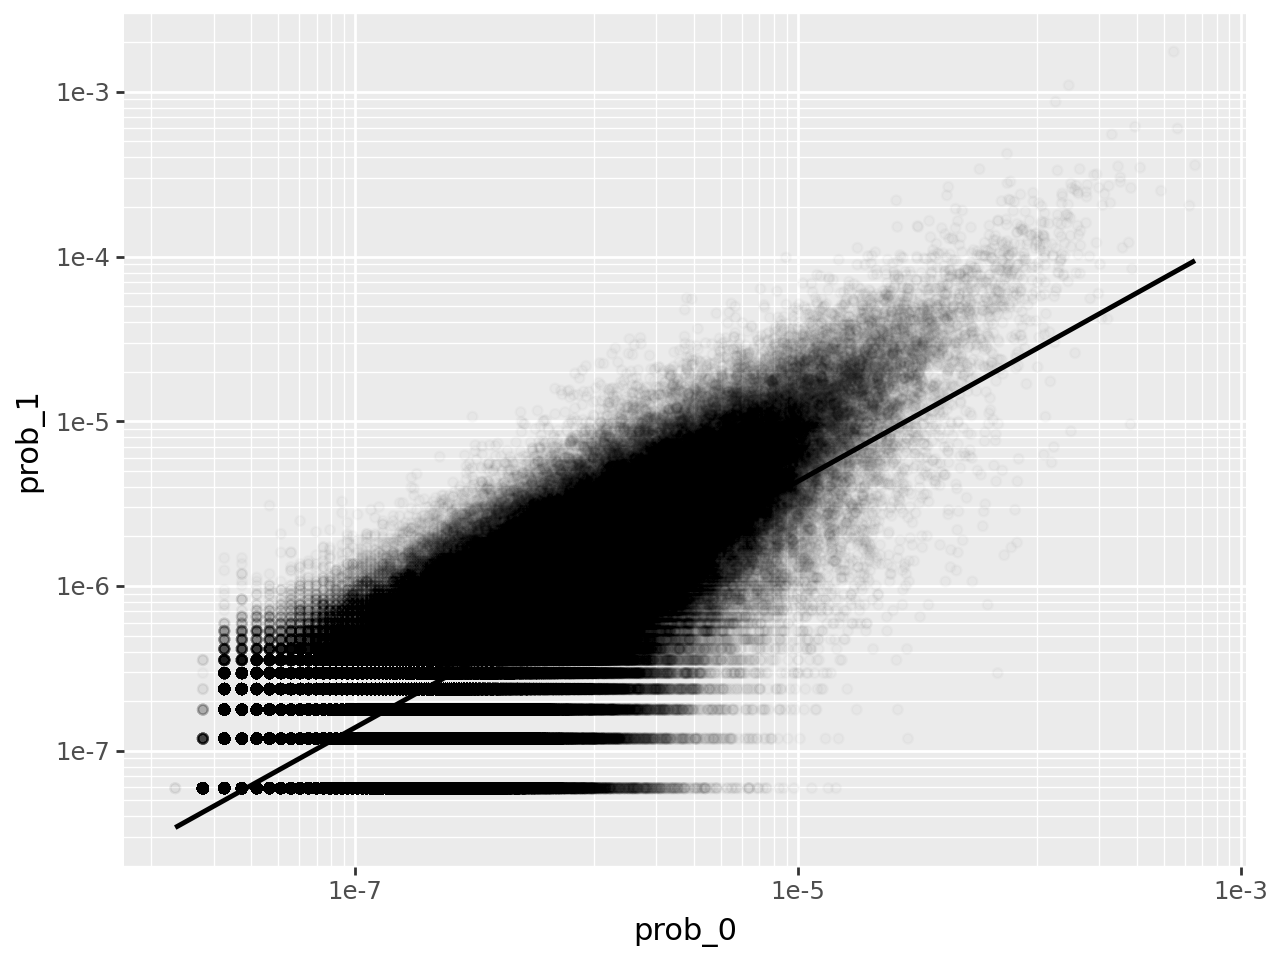

In [13]:
import plotnine as p9
p9.ggplot(aid_popularity.sample(1e6),p9.aes(x="prob_0", y="prob_1"))+p9.geom_point(alpha=.02)+p9.scale_x_log10()+p9.scale_y_log10()+p9.geom_smooth()

probabilities roughly correlated - and same order (click = 0, add-to-cart=1)

a) probability of click given previous

b) ~effect of session length on purchasing~

In [19]:
sessions = train.get_column("session").unique()
sessions_sample = train.get_column("session").sample(10000).unique()

In [20]:
sessions_sample.head()

session
i32
48
50
432
501
1385
1872
2596
2976
3205


In [33]:
train_select = train.filter(pl.col("session").is_in(sessions_sample))

/tmp/ipykernel_8448/1528928892.py:1: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.


In [23]:
train_select.shape

(846878, 4)

In [34]:
train_select.head()

session,aid,ts,type
i32,i32,datetime[μs],enum
48,7903,2022-07-31 22:00:00,"""click"""
48,330002,2022-07-31 22:01:10,"""click"""
48,1267151,2022-07-31 22:01:33,"""click"""
48,1267151,2022-07-31 22:02:36,"""cart"""
48,1140682,2022-07-31 22:02:58,"""click"""


In [47]:
purchases = train.group_by("session").agg(pl.col("type").len().alias("session_length"),(pl.col("type")=='buy').sum().alias("purchases"))

In [36]:
purchases.head()

session,session_length,purchases
i32,u32,u32
6037041,41,0
2437713,31,0
5142268,45,3
5557272,273,3
913107,174,8


In [50]:
purchase_session_lengths = (
    purchases
    .group_by("session_length")
    .agg(pl.col("purchases").sum())
    .sort("session_length")
    .with_columns(cum_purchases=pl.col("purchases").cum_sum(), cum_purchases_prop=pl.col("purchases").cum_sum()/pl.col("purchases").sum())
)

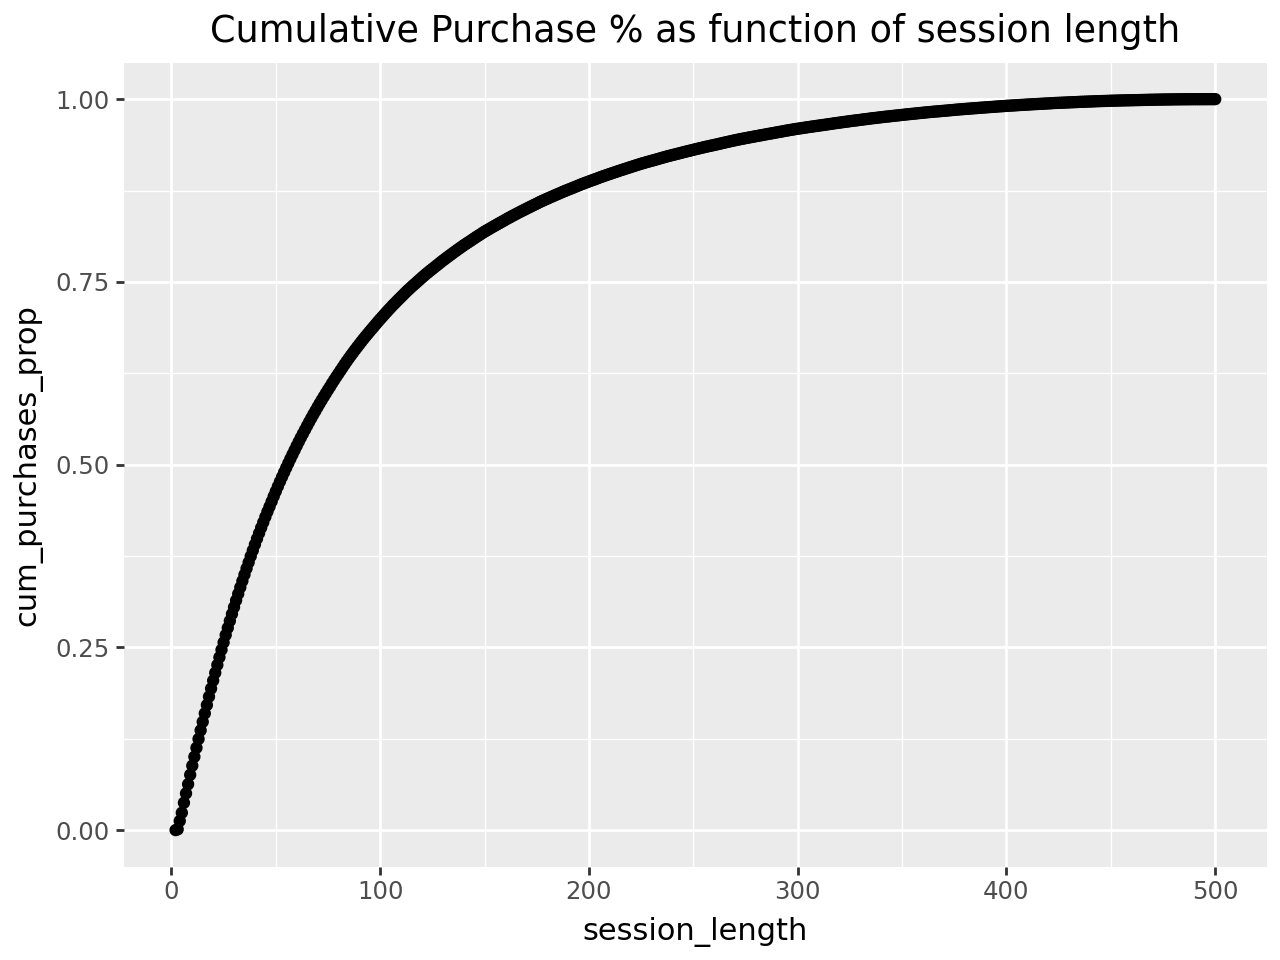

In [51]:
p9.ggplot(purchase_session_lengths, p9.aes(x="session_length", y="cum_purchases_prop"))+p9.geom_point() +p9.ggtitle("Cumulative Purchase % as function of session length")

25% of of purchases in sessions of under 25, 50% in under 50, 75% in under 120, tail is 500

In [10]:
del train

## Covisitation matrices

In [1]:
import polars as pl
import polars_ds as pds

In [4]:
type_map = dict(zip([0,1,2],["clicks","carts","orders"]))
type_e = pl.Enum(type_map.values())


In [2]:
pl.scan_parquet("data/train.parquet").head(10).collect()

session,aid,ts,type
i32,i32,i32,u8
0,1517085,1659304800,0
0,1563459,1659304904,0
0,1309446,1659367439,0
0,16246,1659367719,0
0,1781822,1659367871,0
0,1152674,1659367885,0
0,1649869,1659369893,1
0,461689,1659369898,1
0,305831,1659370027,2


### CPU-90

In [5]:
aid_diff_filter = pl.col("aid")!=pl.col("aid_y")

In [ ]:
cpu_90_carts_orders =  (
    pl.scan_parquet("data/train.parquet")
    .with_columns(type=pl.col("type").cast(type_e))
    .filter(pl.col("type").is_in(["carts","orders"]))
)

days14_filter = ((pl.col("ts")-pl.col("ts_y")).abs()) <= pl.duration(days=14)


covisits_lzy = (
    cpu_90_carts_orders
    .join(cpu_90_carts_orders,on="session",suffix="_y")
    .filter(days14_filter & aid_diff_filter)
    .unique(subset = ["session","aid", "aid_y"]) # 1 pair per session
    .group_by(["aid", "aid_y"]).len()
    .rename({"len": "session_count"})
)

In [11]:
covisits_cpu_90 = covisits_lzy.collect(engine='streaming')

polars 1 minute

pandas CPU times: user 6min 2s, sys: 8.85 s, total: 6min 11s
Wall time: 6min 8s

In [21]:
covisits_cpu_90.shape

(131941668, 3)

In [27]:
covisits_cpu_90.get_column("aid").n_unique()

1188143

In [86]:
covisits_cpu_90_top_40 = (
    covisits_cpu_90
    .select(
        pl.all().top_k_by('session_count',40)
        .over('aid',mapping_strategy='explode'))
)

In [87]:
covisits_cpu_90.filter(pl.col('aid')==351335).sort('session_count',descending=True)

aid,aid_y,session_count
i32,i32,u32
351335,80222,780
351335,549733,26
351335,1060453,15
351335,883703,14
351335,984362,13
…,…,…
351335,1669298,1
351335,203124,1
351335,1327637,1


In [88]:
covisits_cpu_90_top_40.filter(pl.col('aid')==351335)

aid,aid_y,session_count
i32,i32,u32
351335,80222,780
351335,549733,26
351335,1060453,15
351335,883703,14
351335,984362,13
…,…,…
351335,703711,6
351335,673407,6
351335,1658239,6


### CPU-95

In [1]:
import polars as pl
import polars_ds as pds

In [2]:
pl.scan_parquet("data/train.parquet").head(10).collect()

session,aid,ts,type
i32,i32,datetime[μs],enum
0,1517085,2022-07-31 22:00:00,"""clicks"""
0,1563459,2022-07-31 22:01:44,"""clicks"""
0,1309446,2022-08-01 15:23:59,"""clicks"""
0,16246,2022-08-01 15:28:39,"""clicks"""
0,1781822,2022-08-01 15:31:11,"""clicks"""
0,1152674,2022-08-01 15:31:25,"""clicks"""
0,1649869,2022-08-01 16:04:53,"""carts"""
0,461689,2022-08-01 16:04:58,"""carts"""
0,305831,2022-08-01 16:07:07,"""orders"""


In [ ]:
pl.Config.set_streaming_chunk_size(1_000) # didn't work

polars.config.Config

In [ ]:
cpu_95_tail_30 =  (
    pl.scan_parquet("data/train.parquet")
    .set_sorted('session')
    .group_by("session").tail(30)
    
)

aid_diff_filter = pl.col("aid")!=pl.col("aid_y")
covisits_95_lzy = (
    cpu_95_tail_30
    .join(cpu_95_tail_30,on="session",suffix="_y")
    .filter(aid_diff_filter)
    .unique(subset = ["session","aid", "aid_y"]) # 1 pair per session (?random time then if duplicate)
    .group_by(["aid", "aid_y"]).agg(
        ((1/2)**((pl.col('ts')-pl.col('ts_y'))/pl.duration(hours=1))*pl.when(pl.col('type')=='clicks').then(1).otherwise(4)).alias('weight').sum()
    )
)
# couldn't get streaming to work (even setting chunk size to 1000)

In [3]:
aid_diff_filter = pl.col("aid")!=pl.col("aid_y")
cpu_95_tail_30 =  (
    pl.read_parquet("data/train.parquet")
    .set_sorted('session')
    .group_by("session").tail(30)
    
)
dfs = {}
for gp, df in cpu_95_tail_30.group_by(pl.col('session')//10_000):
    dfs[gp] = (
#covisits_95_lzy = (
    df
    .join(df,on="session",suffix="_y")
    .filter(aid_diff_filter)
    .unique(subset = ["session","aid", "aid_y"]) # 1 pair per session (?random time then if duplicate)
    .group_by(["aid", "aid_y"]).agg(
        ((1/2)**((pl.col('ts')-pl.col('ts_y'))/pl.duration(hours=1))*pl.when(pl.col('type')=='clicks').then(1).otherwise(4)).alias('weight').sum()
    )
)

In [6]:
cpu_95_tail_30.shape

(134701339, 4)

pandas CPU times: user 2h 56min 20s, sys: 42.6 s, total: 2h 57min 3s
Wall time: 3h 27s

In [4]:
covisits_95 = pl.concat(dfs.values())

In [18]:
covisits_95.write_parquet('data/covisits_95.parquet')

In [ ]:
# then output top 40 by weight 

In [5]:
covisits_95.head()

aid,aid_y,weight
i32,i32,f64
1650591,260159,5.1099e-138
1810082,1221183,0.96985
1344594,967073,2.8292e8
719816,693964,0.949525
1712751,1030727,1.4666e-19


#### test values

In [17]:
zz = (
    cpu_95_tail_30
    .filter(pl.col('aid').is_in([1810082,1221183]))
)
zz = (
    zz
    .join(zz,on='session', suffix='_y')
    .filter(aid_diff_filter)
    .with_columns(hour_diff = (pl.col('ts') - pl.col('ts_y'))/pl.duration(hours=1))
    .with_columns(weight = pl.when(pl.col('type')=='clicks').then(1).otherwise(4)*(1/2)**pl.col('hour_diff').abs())
)
zz

session,aid,ts,type,aid_y,ts_y,type_y,hour_diff,weight
i32,i32,datetime[μs],enum,i32,datetime[μs],enum,f64,f64
5516442,1221183,2022-08-08 16:57:34,"""clicks""",1810082,2022-08-08 17:00:13,"""clicks""",-0.044167,0.96985
5516442,1810082,2022-08-08 17:00:13,"""clicks""",1221183,2022-08-08 16:57:34,"""clicks""",0.044167,0.96985


In [114]:
zz = (
    cpu_95_tail_30.join(cpu_95_tail_30,on="session",suffix="_y")
    .filter(aid_diff_filter).filter((pl.col('aid')==202774) & (pl.col('aid_y')==1763592)).collect()
)
zz.head()

session,aid,ts,type,aid_y,ts_y,type_y
i32,i32,datetime[μs],enum,i32,datetime[μs],enum
74,202774,2022-08-16 18:20:02,"""clicks""",1763592,2022-08-15 16:44:45,"""clicks"""


In [116]:
1/2**(26)

1.4901161193847656e-08

In [109]:
covisits_95.head()

aid,aid_y,weight
i32,i32,f64
202774,1763592,1.9826e-8
1170985,461203,1.1386e-62
75188,1458643,2.2642e-29
861550,1805466,4.027822
801774,512422,1.3213e-87


## cpu 99

In [3]:
import datetime
import polars as pl
import polars_ds as pds

In [ ]:
id_diff_filter = pl.col("aid")!=pl.col("aid_y")
cpu_99_28_days =  (
    pl.read_parquet("data/train.parquet")
    .set_sorted('session')
    .filter(
        #1662328791
        (pl.col('ts')> datetime.datetime.fromisoformat('2022-09-04 21:59:51') -pl.duration(days=28)) & 
        pl.col('type').is_in(['carts','orders'])
    )
    
)
dfs = {}
for gp, df in cpu_99_28_days.group_by(pl.col('session')//100_000):
    dfs[gp] = (
    df
    .join(df,on="session",suffix="_y")
    .filter(aid_diff_filter)
    .unique(subset = ["session","aid", "aid_y"]) # 1 pair per session (?random time then if duplicate)
    .group_by(["aid", "aid_y"]).agg(
        ((1/2)**((pl.col('ts')-pl.col('ts_y')).abs()/pl.duration(hours=1))).alias('weight').sum()
    )
)

(pandas) CPU times: user 9min 25s, sys: 8.75 s, total: 9min 33s
Wall time: 9min 29s

In [36]:
covisits_99 = pl.concat(dfs.values())

In [37]:
covisits_99.head()

aid,aid_y,weight
i32,i32,f64
82491,180850,3.6480e-7
1633477,683000,1.8201e-11
161081,231487,7.4996e-59
462887,305908,3.2243e-11
49258,1369598,1.9244e-17


In [21]:
pl.from_epoch([1662328791],time_unit='s' )

""
datetime[μs]
2022-09-04 21:59:51


In [46]:
zz = cpu_99_28_days.filter(pl.col('aid').is_in([82491, 180850]))
zz = (
    zz.join(zz,on='session', suffix='_y').filter(aid_diff_filter)
    .unique(subset = ["session","aid", "aid_y"]) # 1 pair per session (?random time then if duplicate)
    .with_columns(((1/2)**((pl.col('ts')-pl.col('ts_y')).abs()/pl.duration(hours=1))).alias('weight'))
)
zz

session,aid,ts,type,aid_y,ts_y,type_y,weight
i32,i32,datetime[μs],enum,i32,datetime[μs],enum,f64
2747050,180850,2022-08-09 03:15:13,"""carts""",82491,2022-08-08 05:52:02,"""carts""",3.6480e-7
2747050,82491,2022-08-08 05:52:02,"""carts""",180850,2022-08-09 03:15:13,"""carts""",3.6480e-7


In [47]:
zz.sum()

session,aid,ts,type,aid_y,ts_y,type_y,weight
i32,i32,datetime[μs],enum,i32,datetime[μs],enum,f64
5494100,263341,null,null,263341,null,null,7.2960e-7


### gpu 93

In [ ]:
zz  = pl.read_parquet('data/train.parquet').head(10_000)


ts
duration[μs]


In [55]:
zz.select(pl.col('ts').diff().over('session')).filter(pl.col('ts')<0).shape

(0, 1)

In [50]:
zz.head()

session,aid,ts,type
i32,i32,datetime[μs],enum
0,1517085,2022-07-31 22:00:00,"""clicks"""
0,1563459,2022-07-31 22:01:44,"""clicks"""
0,1309446,2022-08-01 15:23:59,"""clicks"""
0,16246,2022-08-01 15:28:39,"""clicks"""
0,1781822,2022-08-01 15:31:11,"""clicks"""


In [6]:

tail_30 =  (
    pl.read_parquet("data/train.parquet")
    .set_sorted('session')
    .group_by("session").tail(30)    
)
day_filter = ((pl.col("ts")-pl.col("ts_y")).abs()) <= pl.duration(days=1)
dfs = {}
for gp, df in tail_30.group_by(pl.col('session')//100_000):
    dfs[gp] = (
    df
    .join(df,on="session",suffix="_y")
    .filter(aid_diff_filter & day_filter)
    .unique(subset = ["session","aid", "aid_y"]) # 1 pair per session (?random time then if duplicate)
    .group_by(["aid", "aid_y"]).agg(
        ((1/2)**((pl.col('ts')-pl.col('ts_y')).abs()/pl.duration(hours=1))).alias('weight').sum()
    )
)

        # df['wgt'] = 1 + 3*(df.ts_x - 1659304800)/(1662328791-1659304800)
        # df['wgt'] = df['wgt'] * ((1/2)**( (df.ts_x - df.ts_y).abs() /60/60))
        # df = df[['aid_x','aid_y','wgt']]